# P6 · Morfologi dan pengukuran bercak SIMUTEH

Gunakan dataset SEED 1034 dan parameter praproses P1–P4. Mask acuan dipakai untuk evaluasi. Modul akhir menerima citra praproses dan mengeluarkan ukuran, mask, dan tebakan kelas mutu.

In [1]:
import sys
from pathlib import Path

akar = Path.cwd()
if akar.name == "notebook":
    akar = akar.parent
sys.path.insert(0, str(akar / "src"))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bercak import (BENTUK, PARAM_BERCAK, analisis_daun, bersihkan, elemen,
                    lolos_ambang, simpan_param, ukur_komponen)
from data_simuteh import HASIL, muat_dataset
from tepi import tepi_canny
from utils_cv import tampil
from utils_tepi import bercak_awal, iou, mask_daun_awal, skor_tepi, tepi_acuan

cv2.setNumThreads(1)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 16)


def jumlah(m, konektivitas=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konektivitas)[0] - 1


def simpan_gambar(nama, tampilkan=True):
    plt.savefig(HASIL / nama, dpi=145, bbox_inches="tight", facecolor="white")
    if tampilkan:
        plt.show()
    plt.close()


data = [(d, pra, md, mb, mask_daun_awal(pra)) for d, _, pra, md, mb in muat_dataset()]
contoh = {d.nama_file: (pra, md, mb, daun) for d, pra, md, mb, daun in data}
acu_jumlah = {d.nama_file: jumlah(mb) for d, _, _, mb, _ in data}

## 3. Morfologi

Opening menghapus struktur yang terlalu kecil untuk memuat elemen struktur. Closing mengisi celah sempit dan dapat menggabungkan dua komponen yang berdekatan.

         citra  IoU daun  komponen awal  komponen acuan  IoU bercak
0  teh_041.png     0.996            197               8       0.507
1  teh_021.png     0.993             90               1       0.031
2  teh_011.png     0.998            180               0         NaN


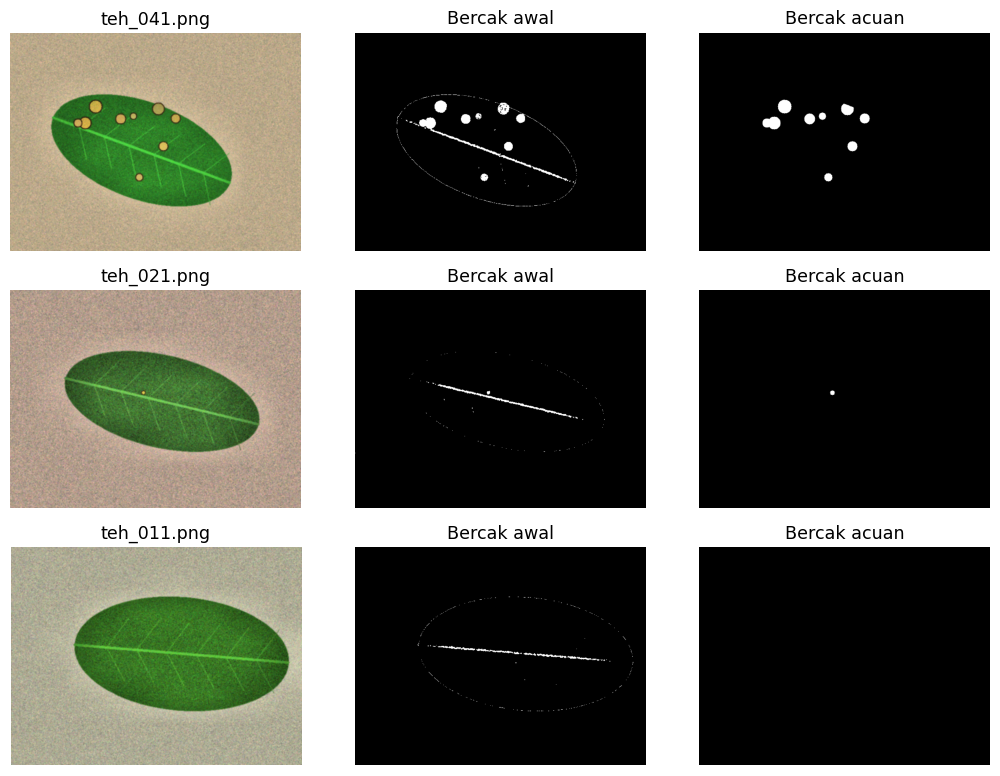

          citra       operasi  komponen  piksel    IoU
0   teh_021.png          awal        90    1380  0.031
1   teh_021.png         erosi        33      66  0.050
2   teh_021.png        dilasi        55    4083  0.020
3   teh_021.png       opening        17     639  0.054
4   teh_021.png       closing        84    1441  0.033
5   teh_021.png  open + close        10     679  0.060
6   teh_011.png          awal       180    1503    NaN
7   teh_011.png         erosi        12      29    NaN
8   teh_011.png        dilasi        72    6089    NaN
9   teh_011.png       opening        10     278    NaN
10  teh_011.png       closing       173    1583    NaN
11  teh_011.png  open + close         9     280    NaN


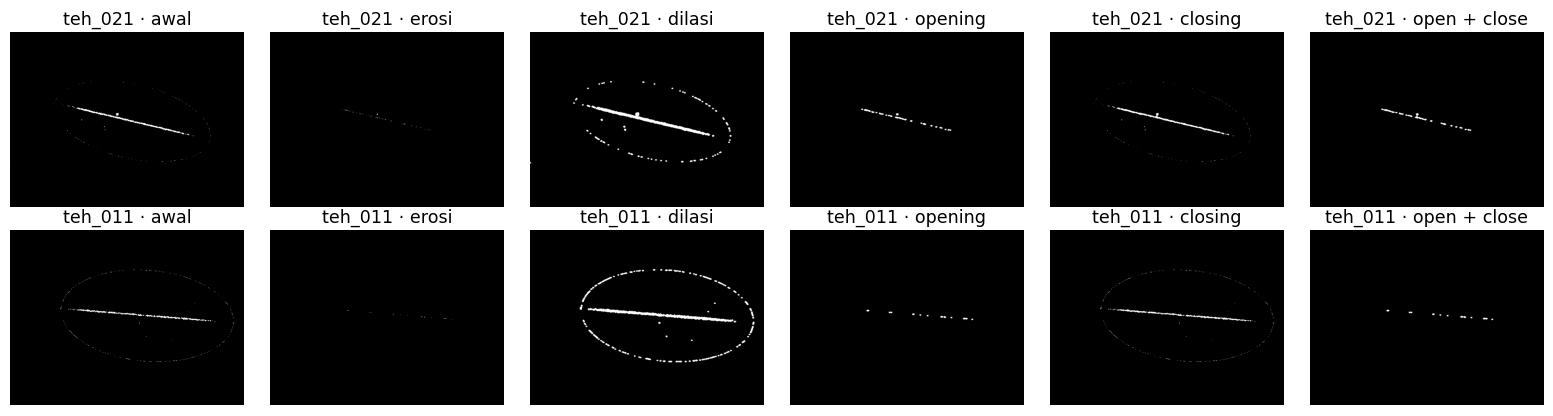

In [2]:
baris, panel, judul = [], [], []
for nama in ("teh_041.png", "teh_021.png", "teh_011.png"):
    pra, md, mb, daun = contoh[nama]
    awal = bercak_awal(pra, daun)
    baris.append([nama, iou(daun, md), jumlah(awal), jumlah(mb), iou(awal, mb) if mb.any() else np.nan])
    panel += [pra, awal, mb]
    judul += [nama, "Bercak awal", "Bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun", "komponen awal", "komponen acuan", "IoU bercak"]).round(3))
tampil(panel, judul, baris=3, ukuran=(10, 7.5))
simpan_gambar("p6_bercak_awal.png")

se5 = elemen("elips", 5)
baris, panel, judul = [], [], []
for nama in ("teh_021.png", "teh_011.png"):
    pra, md, mb, daun = contoh[nama]
    awal = bercak_awal(pra, daun)
    buka = cv2.morphologyEx(awal, cv2.MORPH_OPEN, se5)
    operasi = {"awal": awal, "erosi": cv2.erode(awal, se5), "dilasi": cv2.dilate(awal, se5),
               "opening": buka, "closing": cv2.morphologyEx(awal, cv2.MORPH_CLOSE, se5),
               "open + close": cv2.morphologyEx(buka, cv2.MORPH_CLOSE, se5)}
    for tahap, hasil in operasi.items():
        baris.append([nama, tahap, jumlah(hasil), np.count_nonzero(hasil), iou(hasil, mb) if mb.any() else np.nan])
        panel.append(hasil)
        judul.append(f"{nama[:7]} · {tahap}")
operasi_ringkas = pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"])
print(operasi_ringkas.round(3))
operasi_ringkas.to_csv(HASIL / "p6_operasi.csv", index=False)
tampil(panel, judul, baris=2, ukuran=(15, 4))
simpan_gambar("p6_operasi.png")

Tabel 9 dan pembanding k
                     IoU        galat_jumlah              
kelas             berat ringan        berat ringan  sehat
k bentuk  ukuran                                         
3 elips   3       0.610  0.196        13.65  14.30  28.70
          5       0.631  0.295         3.35   3.15   5.75
          7       0.683  0.409         1.65   1.75   2.20
  persegi 3       0.617  0.235         6.35   5.85   8.30
          5       0.658  0.330         2.90   2.95   4.60
          7       0.679  0.351         0.95   0.90   0.05
  silang  3       0.610  0.196        13.65  14.30  28.70
          5       0.640  0.289         5.65   6.10   9.30
          7       0.697  0.392         3.25   2.70   5.40
4 elips   3       0.658  0.305        11.75  10.85  16.85
          5       0.673  0.369         3.05   3.05   3.50
          7       0.687  0.426         1.35   0.70   0.15
  persegi 3       0.662  0.335         6.40   4.05   9.50
          5       0.687  0.437         1.10   

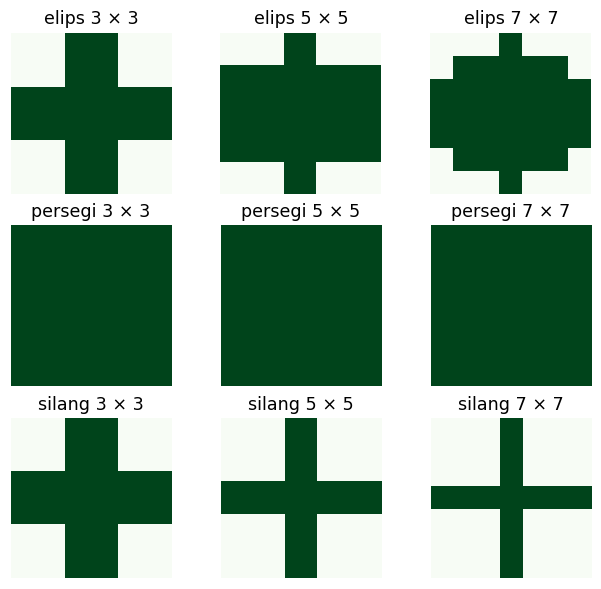

In [3]:
baris, gradien_daun = [], []
for d, pra, md, mb, daun in data:
    for k in (3, 4, 6):
        awal = bercak_awal(pra, daun, k=k)
        for bentuk in BENTUK:
            for ukuran in (3, 5, 7):
                p = {"se_bentuk": bentuk, "se_open": ukuran, "se_close": ukuran}
                mask = bersihkan(awal, p)
                galat = abs(jumlah(mask) - acu_jumlah[d.nama_file])
                baris.append([d.nama_file, d.kelas, k, bentuk, ukuran, galat, iou(mask, mb) if mb.any() else np.nan])
    acuan = tepi_acuan(md)
    gm = cv2.morphologyEx(daun, cv2.MORPH_GRADIENT, elemen("elips", 3))
    canny = tepi_canny(cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY))
    gradien_daun.append([d.nama_file, d.kondisi_cahaya, skor_tepi(gm, acuan)[2], skor_tepi(canny, acuan)[2]])

eks = pd.DataFrame(baris, columns=["citra", "kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
gdaun = pd.DataFrame(gradien_daun, columns=["citra", "kondisi", "F1 morfologi", "F1 Canny"])
assert len(eks) == 60 * 3 * 3 * 3
eks.to_csv(HASIL / "p6_eksperimen_se.csv", index=False)
gdaun.to_csv(HASIL / "p6_gradien_daun.csv", index=False)
tabel9 = eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"])
print("Tabel 9 dan pembanding k\n", tabel9.round(3))
print("\nBatas daun menurut kondisi\n", gdaun.groupby("kondisi")[["F1 morfologi", "F1 Canny"]].mean().round(3))

fig, axes = plt.subplots(3, 3, figsize=(6, 5.5), layout="constrained")
for i, bentuk in enumerate(BENTUK):
    for j, ukuran in enumerate((3, 5, 7)):
        ax = axes[i, j]
        ax.imshow(elemen(bentuk, ukuran), cmap="Greens", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{bentuk} {ukuran} × {ukuran}")
        ax.axis("off")
simpan_gambar("p6_elemen_struktur.png")

## 4. Komponen dan penyaringan

Luas dihitung dari jumlah piksel berlabel. Keliling dan rasio aspek diukur dari kontur. Konversi 0,4375 mm/px berlaku untuk geometri kamera yang ditetapkan dalam modul.

Konektivitas 4 dan 8 [17, 17]
Tabel 10
  label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek  cx  cy
     1      575    110.06        87.60       0.94         1.00 188 162
     2      451     86.32        93.60       0.65         1.00 326 167
     3       71     13.59        33.56       0.79         1.26 269 183
     4      308     58.95        64.53       0.93         1.11 364 188
     5      359     68.71        68.28       0.97         1.00 243 190
     6      664    127.09       106.33       0.74         1.44 160 199
     7       17      3.25        13.66       1.15         1.25 186 221
     8       56     10.72        31.31       0.72         2.74 211 230
     9       22      4.21        15.66       1.13         1.25 228 237
    10      358     68.52       197.48       0.12        15.87 277 254
    11      297     56.85        60.87       1.01         1.00 337 250
    12      136     26.03        83.25       0.25         7.46 339 277
    13       48      9.19        33.8

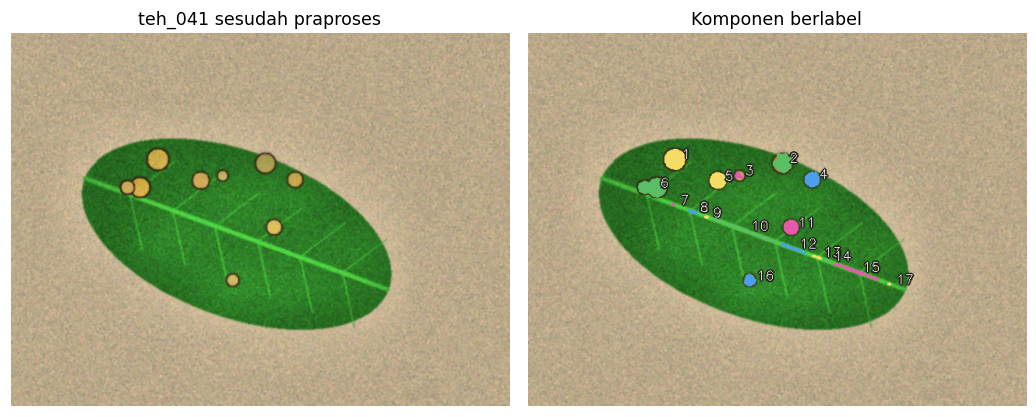

In [4]:
pra, md, mb, daun = contoh["teh_041.png"]
awal = bercak_awal(pra, daun)
bersih = bersihkan(awal, PARAM_BERCAK)
lbl, komponen = ukur_komponen(bersih)
tabel10 = pd.DataFrame(komponen)
print("Konektivitas 4 dan 8", [jumlah(bersih, n) for n in (4, 8)])
print("Tabel 10\n", tabel10.round(2).to_string(index=False))
tabel10.to_csv(HASIL / "p6_teh_041_ukuran.csv", index=False)

warna = pra.copy()
palet = [(100, 220, 245), (100, 190, 90), (170, 90, 230), (235, 160, 75)]
for r in komponen:
    warna[lbl == r["label"]] = palet[(r["label"] - 1) % len(palet)]
    titik = (min(r["cx"] + 9, warna.shape[1] - 23), max(r["cy"], 16))
    cv2.putText(warna, str(r["label"]), titik, cv2.FONT_HERSHEY_SIMPLEX, 0.55, (24, 31, 32), 3)
    cv2.putText(warna, str(r["label"]), titik, cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
tampil([pra, warna], ["teh_041 sesudah praproses", "Komponen berlabel"], ukuran=(10, 3.9))
simpan_gambar("p6_teh_041_label.png")

Tabel 11
 kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.00    1.35   1.45
luas + kebulatan + rasio   1.00    0.45   0.95
luas ≥ 20                  1.75    2.30   2.05
tanpa saring               3.05    3.05   3.50

Daun sehat dengan ≥ 1 komponen palsu
 aturan
luas + kebulatan            10
luas + kebulatan + rasio    10
luas ≥ 20                   11
tanpa saring                13
Name: palsu, dtype: int64


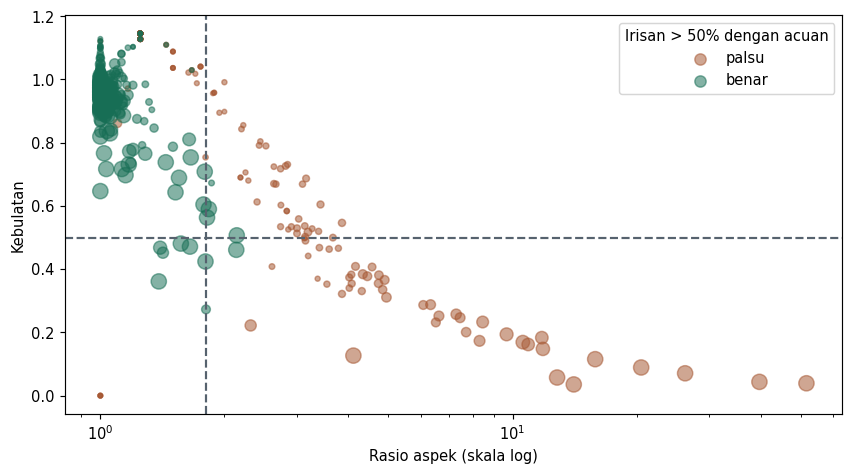

In [5]:
aturan = {"tanpa saring": None, "luas ≥ 20": (20, 0, float("inf")),
          "luas + kebulatan": (20, .5, float("inf")), "luas + kebulatan + rasio": (20, .5, 1.8)}
baris, semua_komponen = [], []
for d, pra, md, mb, daun in data:
    bersih = bersihkan(bercak_awal(pra, daun), PARAM_BERCAK)
    lbl, komponen = ukur_komponen(bersih)
    tumpang_tindih = np.bincount(lbl[mb > 0], minlength=len(komponen) + 1)
    for r in komponen:
        rasio = tumpang_tindih[r["label"]] / r["luas_px"]
        semua_komponen.append({**r, "citra": d.nama_file, "kelas": d.kelas, "irisan": rasio,
                               "status": "benar" if rasio > .5 else "palsu"})
    for nama, nilai in aturan.items():
        if nilai is None:
            hitung = len(komponen)
        else:
            p = dict(zip(("luas_min", "bulat_min", "rasio_maks"), nilai))
            hitung = sum(lolos_ambang(r, p) for r in komponen)
        acuan = acu_jumlah[d.nama_file]
        baris.append([d.nama_file, d.kelas, nama, hitung, acuan, abs(hitung - acuan)])

uji = pd.DataFrame(baris, columns=["citra", "kelas", "aturan", "jumlah", "acuan", "galat"])
kom = pd.DataFrame(semua_komponen)
uji.to_csv(HASIL / "p6_penyaringan.csv", index=False)
kom.to_csv(HASIL / "p6_komponen_benar_palsu.csv", index=False)
print("Tabel 11\n", uji.pivot_table(index="aturan", columns="kelas", values="galat").round(3))
print("\nDaun sehat dengan ≥ 1 komponen palsu\n", uji.query("kelas == 'sehat'").assign(palsu=lambda d: d.jumlah > 0).groupby("aturan").palsu.sum())

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
for status, warna in [("palsu", "#a65732"), ("benar", "#176e55")]:
    bagian = kom[kom.status == status]
    ax.scatter(bagian.rasio_aspek, bagian.kebulatan, s=np.clip(bagian.luas_px / 3, 10, 110),
               color=warna, alpha=.53, label=status)
ax.axhline(.5, color="#56626e", linestyle="--")
ax.axvline(1.8, color="#56626e", linestyle="--")
ax.set(xlabel="Rasio aspek (skala log)", ylabel="Kebulatan", xscale="log")
ax.legend(title="Irisan > 50% dengan acuan")
simpan_gambar("p6_sebar_komponen.png")

## 5. Evaluasi modul akhir

Pertahankan ambang kelas panduan agar hasil dapat dibandingkan. Performa di sini bersifat deskriptif karena pemilihan parameter dan pengukuran memakai dataset sintetis yang sama.

Perbandingan kandidat elips dengan ambang kelas tetap
    k  ukuran  benar  luput  MAE_poin
0  4       5     52      4     0.718
1  4       7     51      6     0.740
2  6       3     54      4     0.623
3  6       5     50      6     0.776
4  3       7     47      4     0.706
Galat absolut rata-rata (poin persentase) 0.623
Korelasi Pearson 0.981
Akurasi kelas 0.9

Matriks kekeliruan
 kelas_prediksi  Sehat  Bercak Ringan  Bercak Berat
kelas_acuan                                       
Sehat              20              0             0
Bercak Ringan       4             16             0
Bercak Berat        0              2            18

Akurasi per kondisi
 kondisi
bayangan          0.833
gelap             1.000
kontras_rendah    0.750
normal            0.917
terang            1.000
Name: benar, dtype: float64


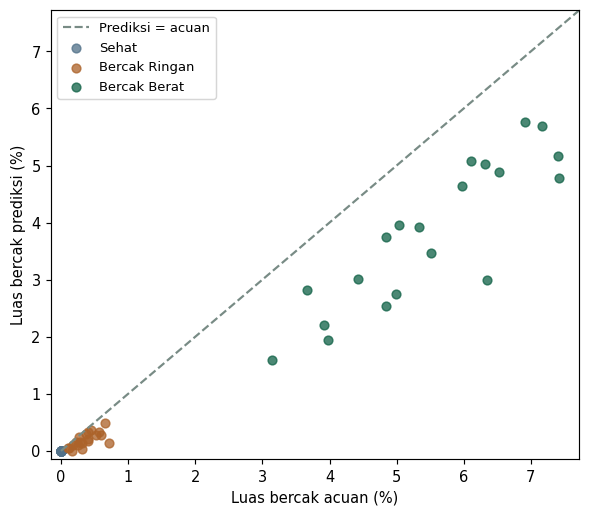

In [6]:
kelas_urut = ["Sehat", "Bercak Ringan", "Bercak Berat"]
nama_kelas = dict(zip(("sehat", "ringan", "berat"), kelas_urut))
kandidat = [(4, 5), (4, 7), (6, 3), (6, 5), (3, 7)]
banding = []
for k, ukuran in kandidat:
    p = {"k": k, "se_open": ukuran, "se_close": ukuran}
    benar, luput, galat = 0, 0, []
    for d, pra, _, _, _ in data:
        h = analisis_daun(pra, p)
        benar += h["kelas"] == nama_kelas[d.kelas]
        luput += d.kelas != "sehat" and h["kelas"] == "Sehat"
        galat.append(abs(h["persen_bercak"] - d.persen_bercak))
    banding.append([k, ukuran, benar, luput, np.mean(galat)])
banding = pd.DataFrame(banding, columns=["k", "ukuran", "benar", "luput", "MAE_poin"])
print("Perbandingan kandidat elips dengan ambang kelas tetap\n", banding.round(3))
banding.to_csv(HASIL / "p6_kandidat_final.csv", index=False)

PB = {"k": 6.0, "se_open": 3, "se_close": 3}
p_final = {**PARAM_BERCAK, **PB}
simpan_param(PB, HASIL / "param_bercak.json")
baris, salah_panel = [], []
for d, pra, md, mb, daun in data:
    hasil = analisis_daun(pra, PB)
    mask = hasil["mask_bercak"]
    awal = bercak_awal(pra, daun, kanal=p_final["kanal"], k=p_final["k"])
    bersih = cv2.bitwise_and(bersihkan(awal, p_final), daun)
    acuan = nama_kelas[d.kelas]
    prediksi = hasil["kelas"]
    tp = np.count_nonzero((mask > 0) & (mb > 0))
    fp = np.count_nonzero((mask > 0) & (mb == 0))
    fn = np.count_nonzero((mask == 0) & (mb > 0))
    baris.append([d.nama_file, d.kondisi_cahaya, acuan, prediksi, d.persen_bercak, hasil["persen_bercak"],
                  acu_jumlah[d.nama_file], hasil["jumlah_bercak"], iou(daun, md), iou(awal, mb),
                  tp, fp, fn, np.count_nonzero((awal > 0) & (mb > 0)), np.count_nonzero((awal > 0) & (mb == 0)),
                  np.count_nonzero((bersih > 0) & (mb > 0)), np.count_nonzero((bersih > 0) & (mb == 0))])
    if acuan != prediksi:
        salah_panel.append((d.nama_file, pra, mask, mb, acuan, prediksi))

ev = pd.DataFrame(baris, columns=["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan", "persen_prediksi",
                                 "jumlah_acuan", "jumlah_prediksi", "IoU_daun", "IoU_awal", "TP_px", "FP_px", "FN_px",
                                 "TP_awal_px", "FP_awal_px", "TP_bersih_px", "FP_bersih_px"])
ev["benar"] = ev.kelas_acuan == ev.kelas_prediksi
ev["galat_persen"] = (ev.persen_prediksi - ev.persen_acuan).abs()
assert len(ev) == 60 and len(salah_panel) == (~ev.benar).sum()
ev.to_csv(HASIL / "p6_evaluasi_bercak.csv", index=False)
matriks = pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi).reindex(index=kelas_urut, columns=kelas_urut, fill_value=0)
print("Galat absolut rata-rata (poin persentase)", round(ev.galat_persen.mean(), 3))
print("Korelasi Pearson", round(ev.persen_acuan.corr(ev.persen_prediksi), 3))
print("Akurasi kelas", round(ev.benar.mean(), 3))
print("\nMatriks kekeliruan\n", matriks)
print("\nAkurasi per kondisi\n", ev.groupby("kondisi").benar.mean().round(3))

fig, ax = plt.subplots(figsize=(5.5, 4.8), layout="constrained")
batas = max(ev.persen_acuan.max(), ev.persen_prediksi.max()) + .3
ax.plot([0, batas], [0, batas], linestyle="--", color="#788b85", label="Prediksi = acuan")
for kelas, warna in zip(kelas_urut, ["#527189", "#ac632a", "#126348"]):
    subset = ev[ev.kelas_acuan == kelas]
    ax.scatter(subset.persen_acuan, subset.persen_prediksi, label=kelas, alpha=.76, color=warna)
ax.set(xlabel="Luas bercak acuan (%)", ylabel="Luas bercak prediksi (%)", xlim=(-.15, batas), ylim=(-.15, batas))
ax.legend(fontsize=9)
simpan_gambar("p6_persen_acuan_prediksi.png")

       nama        kondisi   kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  TP_px  FP_px  FN_px  TP_awal_px
teh_021.png         normal Bercak Ringan          Sehat          0.12            0.049     34      0     47          35
teh_024.png kontras_rendah Bercak Ringan          Sehat          0.32            0.037     28      0    222          42
teh_034.png kontras_rendah Bercak Ringan          Sehat          0.17            0.000      0      0    113           8
teh_040.png       bayangan Bercak Ringan          Sehat          0.11            0.047     36      0     45          37
teh_054.png kontras_rendah  Bercak Berat  Bercak Ringan          3.98            1.941   1724      0   1844        1938
teh_055.png       bayangan  Bercak Berat  Bercak Ringan          3.15            1.590   1239      0   1226        1577


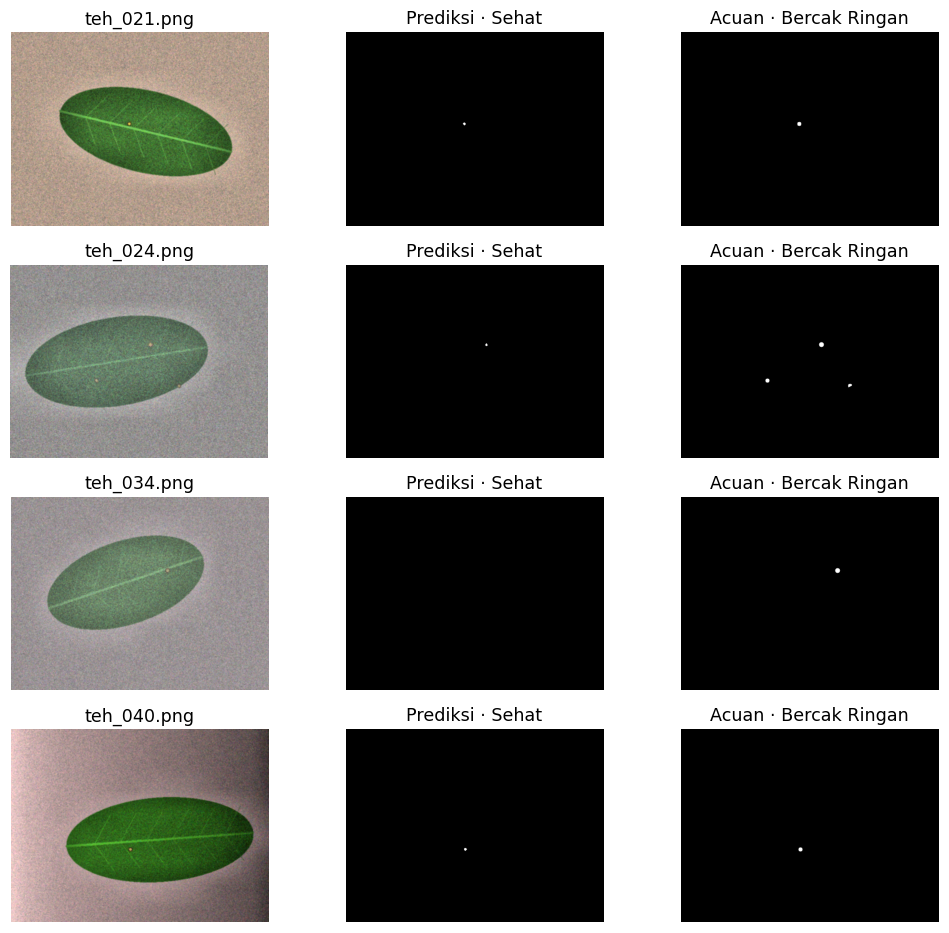

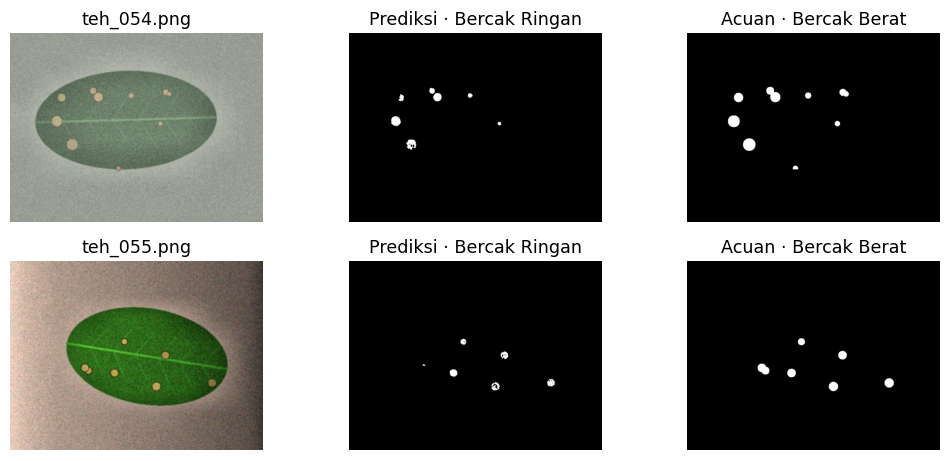

In [7]:
print(ev.loc[~ev.benar, ["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan", "persen_prediksi",
                         "TP_px", "FP_px", "FN_px", "TP_awal_px"]].to_string(index=False))
for nama, pra, mask, mb, acuan, prediksi in salah_panel:
    tampil([pra, mask, mb], [nama, f"Prediksi · {prediksi}", f"Acuan · {acuan}"], ukuran=(10, 2.8))
    simpan_gambar(f"p6_salah_{Path(nama).stem}.png", tampilkan=False)

for awal in range(0, len(salah_panel), 4):
    kelompok = salah_panel[awal:awal + 4]
    citra = [im for _, pra, mask, mb, _, _ in kelompok for im in (pra, mask, mb)]
    judul = [j for nama, _, _, _, acuan, prediksi in kelompok for j in (nama, f"Prediksi · {prediksi}", f"Acuan · {acuan}")]
    tampil(citra, judul, baris=len(kelompok), ukuran=(10, 2.25 * len(kelompok)))
    simpan_gambar(f"p6_panel_salah_{awal // 4 + 1:02}.png")